# 📈 Lab 3B: Linear Regression Practice — Advertising & Sales
### Machine Learning | Effat University | Dr. Naila Marir

---

### 💼 The business problem
You work as a **data analyst** for a company. The marketing manager asks you:

> *"We spend money on **TV**, **radio** and **newspaper** ads. Which channel really brings sales?
> And if I give you a budget, can you **predict** how much we will sell?"*

You will answer her using **linear regression** — the same steps you learned in **Lab 3A**.

### 📂 The dataset: Advertising
200 markets. For each market:
| Column | Meaning |
|---|---|
| `TV` | TV advertising budget (in **thousands of $**) |
| `radio` | Radio advertising budget (in thousands of $) |
| `newspaper` | Newspaper advertising budget (in thousands of $) |
| **`sales`** | **Target:** product sales (in **thousands of units**) |

### 📋 How to work
- Each **Task** has an empty code cell `# TODO` → write your code there.
- 💡 **Hints** tell you which step of **Lab 3A** to look at.
- ✍️ Write short answers in the **"Your answer"** cells.

---
## Part 1 — Get the data

### Task 1: Download the dataset and put it in Google Drive
1. Download `Advertising.csv` from this link → right-click → **Save as…**:
   https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv
2. In Google Drive, create the folder `My Drive/ML_Labs/Lab3B/`
3. Upload `Advertising.csv` into it.

### Task 2: Import the libraries
*(Done for you.)*

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", "{:,.2f}".format)

### Task 3: Connect to Google Drive and read the file into a DataFrame called `df`. Show the first 5 rows.
💡 *Hint: Lab 3A, Step 2.2 and 2.3.*

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [26]:
df = pd.read_csv("/content/drive/MyDrive/ML_Labs/Lab3/Advertising.txt")
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.10,37.80,69.20,22.10
1,2,44.50,39.30,45.10,10.40
2,3,17.20,45.90,69.30,9.30
3,4,151.50,41.30,58.50,18.50
4,5,180.80,10.80,58.40,12.90


### Task 4: Remove the useless column
The first column (`Unnamed: 0`) is only a **row number** — it is not a real feature. Remove it.

💡 *Hint: `df.drop(columns=[...])`*

In [27]:
df = df.drop(columns=['Unnamed: 0'])
df.head()

,TV,radio,newspaper,sales
0,230.10,37.80,69.20,22.10
1,44.50,39.30,45.10,10.40
2,17.20,45.90,69.30,9.30
3,151.50,41.30,58.50,18.50
4,180.80,10.80,58.40,12.90


---
## Part 2 — Explore the data

### Task 5: Basic statistics
Print: the number of rows and columns, the column types, the number of missing values, the number of duplicated rows, and the descriptive statistics.

💡 *Hint: Lab 3A, Step 3.1 to 3.4.*

In [28]:
print("Rows: ",df.shape[0])
print("Columns", df.shape[1])

Rows:  200
Columns 4


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [30]:
#df.isnull()
print("Missing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated())

Missing values: 0
Duplicated rows: 0      False
1      False
2      False
3      False
4      False
       ...  
195    False
196    False
197    False
198    False
199    False
Length: 200, dtype: bool


In [31]:
df.describe()

,TV,radio,newspaper,sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.97,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


**Question 1:** On which channel does the company spend the most money on average? And the least?

**✍️ Your answer:**
The company spends the most on TV and the least on radio. Sales is the outcome the company wants to increase, not an advertising channel it spends money on.

### Task 6: Plot each channel against sales
Make 3 scatter plots: `TV` vs `sales`, `radio` vs `sales`, `newspaper` vs `sales`.

💡 *Hint: Lab 3A, Step 3.7. You can use `plt.subplots(1, 3, figsize=(15, 4))`.*

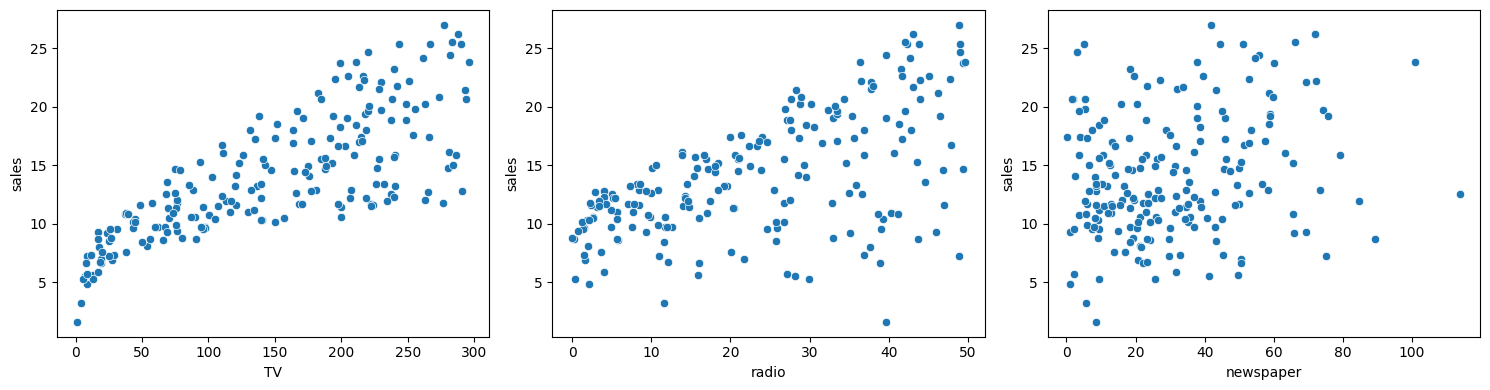

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1
sns.scatterplot(data=df, x="TV", y="sales", ax=axes[0])

# Plot 2
sns.scatterplot(data=df, x="radio", y="sales", ax=axes[1])

# Plot 3
sns.scatterplot(data=df, x="newspaper", y="sales", ax=axes[2])

plt.tight_layout()
plt.show()

### Task 7: Correlation with sales
Show the correlation of each column with `sales`, sorted.

💡 *Hint: Lab 3A, Step 4.3.*

In [44]:
df.corr()["sales"].sort_values(ascending=False)

,sales
sales,1.00
TV,0.78
radio,0.58
newspaper,0.23


**Question 2:** Looking at the plots and the correlations, which channel seems to bring the most sales? Which one seems almost useless?

**✍️ Your answer:**
As seen in the scatter plot, TV & sales have a stronger positive relationship than the rest. This suggests that companies spending more on TV advertising tend to have higher sales. Additionally they have a higher correlation score than the rest.
Meanwhile, newspaper and sales have a weak relationship and a very low correlation score with sales = 0.23 so it seems almost useless.

---
## Part 3 — Prepare the data

### Task 8: Create `X` (the 3 channels) and `y` (`sales`). Then split into 80% train / 20% test with `random_state=42`.
💡 *Hint: Lab 3A, Step 4.4 and 4.5.*

In [45]:
X = df.drop(columns=["sales"])   # inputs
y = df["sales"]                  # what we want to predict
print("Features:", list(X.columns))

Features: ['TV', 'radio', 'newspaper']


In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training:", len(X_train), "| Test:", len(X_test))

Training: 160 | Test: 40


### The `evaluate` function
*(Done for you — the same function as in Lab 3A. Run this cell.)*

In [47]:
results = []

def evaluate(name, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)
    r2_train = r2_score(y_train, model.predict(X_tr))

    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2, "Train R2": r2_train})
    print(f"{name}:  MAE = {mae:.3f} | RMSE = {rmse:.3f} | R2 = {r2:.3f} | Train R2 = {r2_train:.3f}")
    return model

---
## Part 4 — Train the models

📖 Reminder — all linear models in scikit-learn: https://scikit-learn.org/stable/modules/linear_model.html

### Task 9: Simple Linear Regression with `TV` only
Train it with `evaluate`, then print the **slope** and the **intercept**.

💡 *Hint: Lab 3A, Model 1. Use `X_train[["TV"]]` and `X_test[["TV"]]`.*

In [50]:
# Use only one column
X_train_TV = X_train[["TV"]]
X_test_TV  = X_test[["TV"]]

# 1. create
model1 = LinearRegression()

# 2. train
model1.fit(X_train_TV, y_train)

# 3. predict
y_pred1 = model1.predict(X_test_TV)

# 4. evaluate
print("MAE  =", round(mean_absolute_error(y_test, y_pred1)))
print("RMSE =", round(np.sqrt(mean_squared_error(y_test, y_pred1))))
print("R2   =", round(r2_score(y_test, y_pred1), 3))

print("\nSlope w     =", round(model1.coef_[0], 2))
print("Intercept b =", round(model1.intercept_, 2))

MAE  = 2
RMSE = 3
R2   = 0.677

Slope w     = 0.05
Intercept b = 7.12


**Question 3:** Explain the slope in business words. *(Remember the units: TV in $1000, sales in 1000 units.)*

**✍️ Your answer:**
For every additional $1,000 spent on TV advertising, predicted sales increase by approximately 50 units, on average

### Task 10: Multiple Linear Regression with all 3 channels
Train it with `evaluate`, then show the weight of each channel.

💡 *Hint: Lab 3A, Model 2.*

In [51]:
model2 = evaluate("2. Multiple LR", LinearRegression(), X_train, X_test)

2. Multiple LR:  MAE = 1.461 | RMSE = 1.782 | R2 = 0.899 | Train R2 = 0.896


In [52]:
pd.Series(model2.coef_, index=X.columns).sort_values()

,0
newspaper,0.00
TV,0.04
radio,0.19


**Question 4:** If the company adds $1,000 to **one** channel, which channel gives the most extra sales? Which one gives almost nothing?

**✍️ Your answer:**
Radio gives the most extra predicted sales for every additional $1,000 spent, while newspaper gives almost no extra predicted sales.
For example, radio's coefficient of 0.19 means about 190 additional units sold because sales are measured in thousands of units.

### Task 11: Polynomial Regression (degree 2)
💡 *Hint: Lab 3A, Model 4.*

In [53]:
model4 = evaluate("4. Polynomial (degree 2)",
                  make_pipeline(PolynomialFeatures(degree=2), StandardScaler(), LinearRegression()),
                  X_train, X_test)

4. Polynomial (degree 2):  MAE = 0.526 | RMSE = 0.643 | R2 = 0.987 | Train R2 = 0.986


**Question 5:** R² jumped a lot. Why? *(Think about Lab 3A: smoker × BMI. Here: what happens when a company advertises on TV **and** radio together?)*

**✍️ Your answer:** Since both TV and radio have a moderate to strong positive relationship with sales, if a company advertises both, they will naturally have more in sales.
The R² increased because Polynomial Regression can learn more complex patterns like nonlinear relations. It considers how advertising channels work together, such as TV and radio, which helps it predict sales more accurately.

### Task 12: Ridge (`alpha=1`) and Lasso (`alpha=0.1`)
Train both with `StandardScaler`. For Lasso, print which feature(s) got a weight of **0**.

💡 *Hint: Lab 3A, Model 5 and Model 6.*

In [54]:
model5 = evaluate("5. Ridge",
                  make_pipeline(StandardScaler(), Ridge(alpha=1)),
                  X_train, X_test)

5. Ridge:  MAE = 1.464 | RMSE = 1.787 | R2 = 0.899 | Train R2 = 0.896


In [58]:
model6 = evaluate("6. Lasso",
                  make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
                  X_train, X_test)

# model6[-1] = the last step of the pipeline (the Lasso model)
weights = pd.Series(model6[-1].coef_, index=X.columns)
print("\nFeatures removed by Lasso:", list(weights[weights == 0].index))

6. Lasso:  MAE = 1.461 | RMSE = 1.791 | R2 = 0.898 | Train R2 = 0.895

Features removed by Lasso: ['newspaper']


**Question 6:** Which channel did Lasso remove? Does it agree with your answers to Questions 2 and 4?

**✍️ Your answer:**
Lasso removed newspaper as expected from previous observations with questions 2 and 4

### Task 13: Discover a new model 🔍
Open https://scikit-learn.org/stable/modules/linear_model.html, choose **one** model we did not use
(for example `HuberRegressor`, `BayesianRidge`, `ElasticNet`), import it and train it with `evaluate` (with `StandardScaler`).

In [61]:
model7 = evaluate(
    "7. ElasticNet",
    make_pipeline(StandardScaler(), ElasticNet()),
    X_train,
    X_test
)

7. ElasticNet:  MAE = 2.419 | RMSE = 2.940 | R2 = 0.726 | Train R2 = 0.739


Elastic-net is useful when there are multiple features that are correlated with one another. Lasso is likely to pick one of these at random, while elastic-net is likely to pick both.


**Question 7:** In 2 sentences: what is the idea of the model you chose, and how did it perform?

**✍️ Your answer:**
ElasticNet combines Lasso and Ridge regularization to reduce model complexity and can be useful when input features are correlated. It performed relatively poorly on my data, with an R² of 0.726, compared with 0.899 for Multiple Linear Regression and 0.987 for Polynomial Regression.

---
## Part 5 — Compare and predict

### Task 14: Show all results in one table sorted by RMSE, and a bar chart of R².
💡 *Hint: Lab 3A, Step 7.*

In [63]:
results_df = pd.DataFrame(results).set_index("Model").sort_values("RMSE")
results_df

,MAE,RMSE,R2,Train R2
Model,,,,
4. Polynomial (degree 2),0.53,0.64,0.99,0.99
2. Multiple LR,1.46,1.78,0.90,0.90
5. Ridge,1.46,1.79,0.90,0.90
6. Lasso,1.46,1.79,0.90,0.89
6. Lasso,1.46,1.79,0.90,0.89
5. ElasticNet,2.42,2.94,0.73,0.74
7. ElasticNet,2.42,2.94,0.73,0.74
Simple LR (TV),2.44,3.19,0.68,0.59
6. Lasso,4.96,5.63,-0.00,0.00


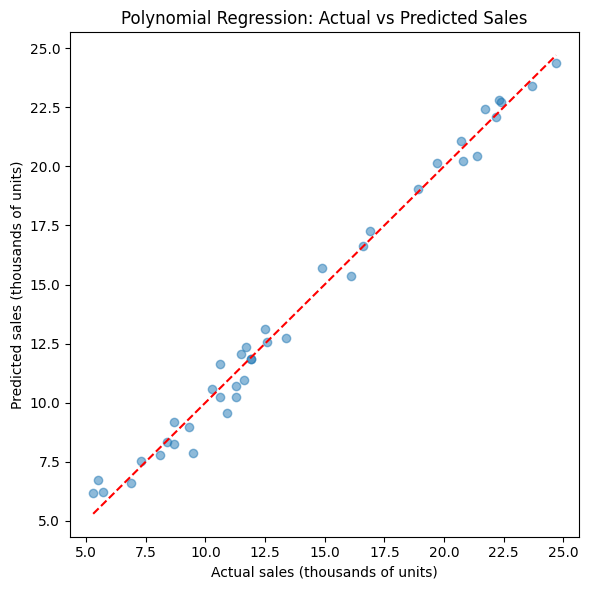

In [65]:
# Use the Polynomial Regression model
best_model = model4
y_pred = best_model.predict(X_test)

# Set the reference line to match the sales data range
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([min_val, max_val], [min_val, max_val],
         color="red", linestyle="--")

plt.xlabel("Actual sales (thousands of units)")
plt.ylabel("Predicted sales (thousands of units)")
plt.title("Polynomial Regression: Actual vs Predicted Sales")
plt.tight_layout()
plt.show()

**Question 8:** Which model is the best? Is it overfitting? *(Compare its R² and Train R².)*

**✍️ Your answer:** The best model based on my experiments is the Polynomial 2-degree model as it has and R2 score of 0.9869 and train R2 = 0.9861 therefore it is not overfitting because the training and test R² scores are very close

### Task 15: Help the manager choose a budget plan 💼
The manager has **$150,000** to spend. She has 3 plans (values in $1000):

| Plan | TV | radio | newspaper |
|---|---|---|---|
| A | 100 | 20 | 30 |
| B | 90 | 45 | 15 |
| C | 150 | 0 | 0 |

Use your **best model** to predict the sales of each plan.

💡 *Hint: Lab 3A, Step 8.3. Build a DataFrame with the columns `TV`, `radio`, `newspaper`.*

In [66]:
new_sales = pd.DataFrame({
    "TV":              [100, 90, 150],
    "radio":              [20, 45, 0],
    "newspaper":         [30, 15, 0],
})

predictions = best_model.predict(new_sales)

# Display each prediction
for i, prediction in enumerate(predictions):
    print(f"Scenario {i + 1}:")
    print(f"TV spending:        ${new_sales['TV'][i]:,.0f},000")
    print(f"Radio spending:     ${new_sales['radio'][i]:,.0f},000")
    print(f"Newspaper spending: ${new_sales['newspaper'][i]:,.0f},000")
    print(f"Predicted sales:    {prediction:.2f} thousand units")
    print(f"                    Approximately {prediction * 1000:,.0f} units")
    print()

Scenario 1:
TV spending:        $100,000
Radio spending:     $20,000
Newspaper spending: $30,000
Predicted sales:    11.95 thousand units
                    Approximately 11,953 units

Scenario 2:
TV spending:        $90,000
Radio spending:     $45,000
Newspaper spending: $15,000
Predicted sales:    14.51 thousand units
                    Approximately 14,509 units

Scenario 3:
TV spending:        $150,000
Radio spending:     $0,000
Newspaper spending: $0,000
Predicted sales:    10.40 thousand units
                    Approximately 10,398 units



**Question 9:** Which plan do you recommend to the manager, and why? Write it as a short message to her (2–3 sentences).

**✍️ Your answer:**
I recommend Plan B because our model predicts the highest sales of approximately 14,509 units with the $150,000 budget. This plan allocates more money to radio advertising, which appears to work well alongside TV advertising, and is predicted to outperform Plans A and C.

**Question 10 (metrics):** Your best model has RMSE ≈ 0.6. Explain this number to the manager in one sentence. *(Remember: sales are in thousands of units.)*

**✍️ Your answer:**
0.6 x 1000 = 600 units
An RMSE of 0.6 means that the model's sales predictions differ from actual sales by around 600 units.

---
## ⭐ Bonus — Polynomial degree 3
Train a polynomial model with `degree=3`. Is it much better than degree 2? Is it worth making the model more complex?

In [67]:
model8 = evaluate("8. Polynomial (degree 3)",
                  make_pipeline(PolynomialFeatures(degree=3), StandardScaler(), LinearRegression()),
                  X_train, X_test)

8. Polynomial (degree 3):  MAE = 0.389 | RMSE = 0.543 | R2 = 0.991 | Train R2 = 0.992


Degree 3 performs slightly better than degree 2: its R² increases from 0.987 to 0.991, and its RMSE decreases from 0.643 to 0.543 thousand units. However, the improvement is relatively small, so degree 2 may be preferable because it is simpler, although degree 3 shows no obvious sign of overfitting based on the similar training and test R² scores.

---
### 📤 Submission
File → Download → `.ipynb`, name it `Lab3B_YourName.ipynb`, and upload it to Blackboard.